In [1]:
from keras.layers import Conv2D, Dropout, Input, ZeroPadding2D, BatchNormalization, Activation, MaxPooling2D, Flatten, Dense
from tensorflow.keras.callbacks import TensorBoard, ModelCheckpoint
from keras.preprocessing.image import ImageDataGenerator
from keras.models import Model, load_model
from tensorflow.keras import layers
from keras.models import Sequential
from sklearn.utils import shuffle
import matplotlib.pyplot as plt
from tensorflow import keras
from keras import optimizers 
from keras import metrics 
from keras import losses 
import tensorflow as tf
from os import listdir
import numpy as np
import PIL
import cv2
import time
import glob
import os
print(os.getcwd()) 


Using TensorFlow backend.


C:\Users\Dell\Envs\PES_AI_PIP


In [128]:
# To be executed by changing the number_of_augs accordingly  (only once)
#data_gen = ImageDataGenerator(    rotation_range=10, 
#                                  width_shift_range=0.05, 
#                                   height_shift_range=0.05, 
#                                  shear_range=0.1, 
#                                  fill_mode='nearest',
#                                  interpolation_order=5
#                              )
#print(os.getcwd()) 
#os.chdir("../")

###augmented_image_paths=glob.glob(r'C:\Users\Dell\Envs\PES_AI_PIP\Train_Data_31\**\*DWI.jpg', recursive=True)
#augmented_image_paths=pathlib.Path('.')/"Merged_Data" 

#number_of_augs=10
#for name in augmented_image_paths:
#    image_path=name
#    image=cv2.imread(image_path)
#    image = image.reshape((1,)+image.shape)
#    save_image_as = 'Aug_'+ image_path.split('\\')[-1][:-4]
#    save_folder_as=image_path.split('\Case')[0]
#    i=1
#    for batch in data_gen.flow(x=image, batch_size=1, save_to_dir=save_folder_as, save_prefix=save_image_as, save_format='jpg'):
#        i += 1
#        if i>number_of_augs:
#            break


In [22]:
def labels_list(image_path_list):
    label_list=[]
    for image_path in image_path_list:
        label=image_path.split('\\')[-2]
        label_list.append(label)
    return label_list

#to return a nuemeric label i.e. index of it in the folders list
def label_map(image_path,label_name_list):
    label_name=image_path.split('\\')[-2]
    return label_name_list.index(label_name)

def find_index(image_path):
    i=image_path.split('\\')[-2]
    
    if i=='Bilateral cerebellar hemispheres': 
        return 0
    if i=='Bilateral frontal lobes':
        return 1
    if i=='Bilateral occipital lobes':
        return 2
    if i=='Brainstem':
        return 3
    if i=='Dorsal aspect of pons': 
        return 4
    if i=='Left centrum semi ovale and right parietal lobe':
        return 5
    if i=='Left cerebellar':
        return 6
    if i=='Left corona radiata':    
        return 7
    if i=='Left frontal lobe':  
        return 8
    if i=='Left frontal lobe in precentral gyral location':
        return 9
    if i=='Left fronto parietal':
        return 10
    if i=='Left insula':
        return 11
    if i=='Left occipital and temporal lobes':
        return 12
    if i=='Left occipital lobe':
        return 13
    if i=='Left parietal lobe':
        return 14
    if i=='Left thalamic':
        return 15
    if i=='Medial part of right frontal and parietal lobes':
        return 16
    if i=='Medula oblongata-left':
        return 17
    if i=='Mid brain on right side':
        return 18
    if i=='Pons-left':
        return 19
    if i=='Pontine-right':
        return 20
    if i=='Posterior limb of left internal capsule':
        return 21
    if i=='Right anterior thalamic': 
        return 22
    if i=='Right cerebellar hemisphere': 
        return 23
    if i=='Right corona radiata':
        return 24
    if i=='Right frontal lobe':  
        return 25
    if i=='Right fronto-parieto-temporo- occipital lobes':      
        return 26
    if i=='Right ganglio-capsular region':
        return 27
    if i=='Right insula': 
        return 28
    if i=='Right lentiform nucleus':   
        return 29
    if i=='Right occipital lobe':
        return 30
    if i=='Right parietal lobe':   
        return 31
    if i=='Right putamen':  
        return 32
    if i=='Right temporal lobe': 
        return 33
    if i=='Right thalamus':
        return 34
    if i=='Splenium of the corpus callosum': 
        return 35
    
def load_data(image_path_list, image_size, label_name_list):
    X = []
    y = []
    image_width, image_height = image_size
    
    for image_path in image_path_list:
        image = cv2.imread(image_path)
        image = cv2.resize(image, dsize=(image_width, image_height), interpolation=cv2.INTER_CUBIC)
        image = image / 255.
        X.append(image)
        #returns the index==label number of brain location folders
        #label_num=label_map(image_path,label_name_list)
        index=find_index(image_path)
        y.append(index)    
        
    X = np.array(X)
    y = np.array(y)
    
    # Shuffle the data
    X, y = shuffle(X, y)
    
    print(f'Number of examples is: {len(X)}')
    print(f'X shape is: {X.shape}')
    print(f'y shape is: {y.shape}')
    #print(y)

    return X, y

path=os.getcwd()
os.chdir("../")
print(os.getcwd()) 

path1=os.path.join(path,"Train_Data_31\**\*.jpg")
path2=os.path.join(path,"test\**\*.jpg")

print(path1)
#train_image_paths_list=glob.glob(r'C:\Users\Dell\Envs\PES_AI_PIP\Train_Data_31\**\*.jpg', recursive=True)
train_image_paths_list=glob.glob(path1, recursive=True)
#test_image_paths_list=glob.glob(r'C:\Users\Dell\Envs\PES_AI_PIP\test\**\*.jpg', recursive=True)
test_image_paths_list=glob.glob(path2, recursive=True)


#returns list of label names of brain location folders i.e. train_image_paths_list=all the possible labels
label_name_list=labels_list(train_image_paths_list)
#label_name_list_test= labels_list(test_image_paths_list)

IMG_WIDTH, IMG_HEIGHT = (128, 128)

X_train, y_train = load_data(train_image_paths_list, (IMG_WIDTH, IMG_HEIGHT), label_name_list)
X_test, y_test = load_data(test_image_paths_list, (IMG_WIDTH, IMG_HEIGHT), label_name_list)



C:\Users\Dell\Envs
C:\Users\Dell\Envs\PES_AI_PIP\Train_Data_31\**\*.jpg
Number of examples is: 1115
X shape is: (1115, 128, 128, 3)
y shape is: (1115,)
Number of examples is: 10
X shape is: (10, 128, 128, 3)
y shape is: (10,)


Instructions for updating:
If using Keras pass *_constraint arguments to layers.


Train on 892 samples, validate on 223 samples
Epoch 1/10
892/892 [==============================] - 18s 20ms/step - loss: 3.3425 - accuracy: 0.1211 - val_loss: 2.6203 - val_accuracy: 0.3139
Epoch 2/10
892/892 [==============================] - 19s 21ms/step - loss: 1.6970 - accuracy: 0.5583 - val_loss: 0.6991 - val_accuracy: 0.8296
Epoch 3/10
892/892 [==============================] - 17s 19ms/step - loss: 0.4540 - accuracy: 0.8890 - val_loss: 0.2875 - val_accuracy: 0.9462
Epoch 4/10
892/892 [==============================] - 16s 18ms/step - loss: 0.2169 - accuracy: 0.9529 - val_loss: 0.1251 - val_accuracy: 0.9821
Epoch 5/10
892/892 [==============================] - 16s 18ms/step - loss: 0.0764 - accuracy: 0.9787 - val_loss: 0.0935 - val_accuracy: 0.9686
Epoch 6/10
892/892 [==============================] - 16s 18ms/step - loss: 0.0446 - accuracy: 0.9888 - val_loss: 0.2778 - val_accuracy: 0.9148
Epoch 7

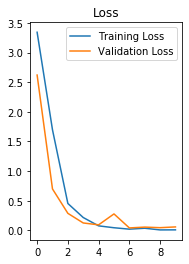

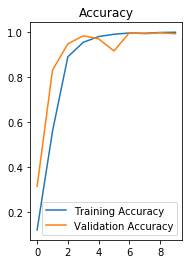

In [23]:
from keras.regularizers import l2
def try_model(X_train,y_train):
    model = Sequential()
    
    model.add(Conv2D(64, kernel_size=(5,5), activation='relu', input_shape=(IMG_WIDTH,IMG_HEIGHT,3)))
    model.add(MaxPooling2D(pool_size=(4,4)))
    model.add(Conv2D(64, kernel_size=(5,5), activation='relu', input_shape=(IMG_WIDTH,IMG_HEIGHT,3)))
    model.add(MaxPooling2D(pool_size=(4,4)))

    model.add(Flatten())

    model.add(Dropout(0,5))
    

    model.add(Dense(36))


    model.add(Activation('softmax'))
    
    model.compile(loss='sparse_categorical_crossentropy',optimizer='rmsprop',metrics=['accuracy'])
    #model.fit(X_train, y_train, batch_size =32,validation_data=(X_val,y_val),epochs=8)
    model.fit(X_train, y_train, batch_size =20,validation_split=0.2,epochs=10)
    return model

mdl=try_model(X_train,y_train)#,X_val,y_val)
print(mdl.summary())

history = mdl.history.history

def plot_metrics(history):
    
    train_loss = history['loss']
    val_loss = history['val_loss']
    train_acc = history['accuracy']
    val_acc = history['val_accuracy']
    
    # Loss
    plt.subplot(121)
    plt.plot(train_loss, label='Training Loss')
    plt.plot(val_loss, label='Validation Loss')
    plt.title('Loss')
    plt.legend()
    plt.show()
    
    # Accuracy
    plt.subplot(122)
    plt.plot(train_acc, label='Training Accuracy')
    plt.plot(val_acc, label='Validation Accuracy')
    plt.title('Accuracy')
    plt.legend()
    plt.show()

plot_metrics(history) 




In [159]:

result = mdl.predict(X_test)
print('\n')
t0=np.argmax(result[0])
t1=np.argmax(result[1])
t2=np.argmax(result[2])
t3=np.argmax(result[3])
t4=np.argmax(result[4])
t5=np.argmax(result[5])
t6=np.argmax(result[6])
t7=np.argmax(result[7])
t8=np.argmax(result[8])
t9=np.argmax(result[9])


print('The predicted output is:')
print(t0,t1,t2,t3,t4,t5,t6,t7,t8,t9)

print('The index must be: ')
print((y_test))

#the predicted result varies each time 
#the best prediction we obtained was 5 out 10 predicted well 



The predicted output is:
13 18 25 15 14 33 24 22 14 21
The index must be: 
[31  6 25 14 10 23 24 33  2  0]


In [160]:
mdl.save('pro_dl.h5')

In [161]:
from keras.models import load_model 
new_model =load_model('pro_dl.h5')

In [162]:
new_model.summary()

Model: "sequential_6"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_11 (Conv2D)           (None, 124, 124, 64)      4864      
_________________________________________________________________
max_pooling2d_11 (MaxPooling (None, 31, 31, 64)        0         
_________________________________________________________________
conv2d_12 (Conv2D)           (None, 27, 27, 64)        102464    
_________________________________________________________________
max_pooling2d_12 (MaxPooling (None, 6, 6, 64)          0         
_________________________________________________________________
flatten_6 (Flatten)          (None, 2304)              0         
_________________________________________________________________
dropout_6 (Dropout)          (None, 2304)              0         
_________________________________________________________________
dense_6 (Dense)              (None, 36)               

In [163]:
new_model.get_weights()

[array([[[[-0.03048623, -0.06736686, -0.02887711, ..., -0.02799914,
           -0.0633299 ,  0.07687653],
          [-0.07727362, -0.04139888, -0.06747209, ...,  0.00953059,
           -0.08567566, -0.00572814],
          [-0.03739366, -0.06547042,  0.02237204, ..., -0.0796643 ,
           -0.06117222,  0.0178015 ]],
 
         [[-0.01562566, -0.04164384, -0.07426731, ..., -0.02740698,
           -0.00261881, -0.01879746],
          [-0.0807768 ,  0.01340769, -0.06681877, ..., -0.03208892,
           -0.09508786, -0.06312788],
          [-0.0165824 ,  0.02502359,  0.04370588, ...,  0.00631749,
           -0.04446022,  0.04394792]],
 
         [[ 0.00053235, -0.04666829, -0.05485948, ..., -0.0575808 ,
           -0.08873474, -0.02191578],
          [ 0.01170407,  0.05022798, -0.05756246, ..., -0.03429212,
           -0.08827578,  0.01205327],
          [-0.0440826 ,  0.02322   , -0.06684605, ..., -0.09706822,
            0.01476847, -0.04335523]],
 
         [[-0.04549547, -0.01962585, 